# Dalitz-plot analysis

This notebook studies the internal three-body kinematics of selected B -> KKK candidates with Dalitz variables. Dalitz plots are a standard tool for visualising resonant substructure and phase-space population in multibody decays.


## Physics motivation

For a three-body decay, two independent pairwise invariant masses fully describe the event position in phase space, up to angular information. Localised structures or bands in a Dalitz plot can indicate intermediate resonances, interference patterns, or non-uniform detector/selection effects.


In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "B2HHH_MagnetDown.root"
FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

DATA_PATH


PosixPath('/Users/yanisidir/lhcb-b2hhh-analysis/data/raw/B2HHH_MagnetDown.root')

In [2]:
import matplotlib.pyplot as plt

from src.physics.selection import load_b2hhh_dataframe, add_b_mass, apply_baseline_selection
from src.physics.dalitz import compute_dalitz_variables, compute_pair_mass
from src.plotting.mass_plots import set_hep_style

set_hep_style()


/Users/yanisidir/.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/9p/pgg9br694897f2trtrc5y97c0000gn/T/matplotlib-ahvlq6zj because there was an issue with the default path (/Users/yanisidir/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories
Fontconfig error: No writable cache directories


Fontconfig error: No writable cache directories


Matplotlib is building the font cache; this may take a moment.


## Load and select candidates

The notebook uses the same ROOT input, B-mass reconstruction, and baseline selection as the rest of the project. This makes the Dalitz distributions directly comparable to the mass and CP-asymmetry studies.


In [3]:
df = load_b2hhh_dataframe(DATA_PATH)
df = add_b_mass(df)
df_sel = apply_baseline_selection(df)

print(f"Loaded candidates:   {len(df):,}")
print(f"Selected candidates: {len(df_sel):,}")
df_sel.head()


Loaded candidates:   5,135,823
Selected candidates: 1,645


,H1_PX,H1_PY,H1_PZ,H2_PX,H2_PY,H2_PZ,H3_PX,H3_PY,H3_PZ,H1_Charge,...,H3_Charge,H1_ProbK,H2_ProbK,H3_ProbK,H1_ProbPi,H2_ProbPi,H3_ProbPi,B_VertexChi2,B_FlightDistance,B_mass
5911,409.597326,-922.895885,20897.310967,1203.071583,-1920.154667,40475.734267,-3459.363958,-2564.626154,75809.047870,-1,...,1,0.922096,0.950725,0.921754,0.059316,0.254305,0.092939,1.044176,53.008846,5278.782080
7561,1896.131812,342.165476,13004.358365,-212.269027,2315.053951,29215.421432,3919.152618,2803.269146,50026.628572,-1,...,1,0.803463,0.769137,0.964152,0.094286,0.038924,0.132662,1.234878,25.028023,5280.889118
8171,2639.151502,4945.908581,36593.572489,1746.893777,2578.755924,19941.038258,2752.570307,6924.039031,87480.913013,1,...,-1,0.586932,0.792148,0.619050,0.093519,0.045532,0.617080,1.396345,26.784880,5310.000362
14006,-580.924639,-3482.868924,42314.120655,1329.515702,-2999.949560,52082.765074,-2272.459558,-2821.365130,73606.673218,-1,...,1,0.953703,0.943361,0.702081,0.114240,0.166630,0.415309,3.868593,21.125746,5252.199904
17076,4662.947762,-1502.073656,27549.868520,-347.144740,-1624.302106,6795.955362,2865.033662,-987.027245,18183.793931,1,...,-1,0.973362,0.693893,0.668686,0.119986,0.045107,0.031975,2.847910,29.216699,5299.993524


## Pairwise invariant masses

The Dalitz variables are the squared invariant masses of the three two-body subsystems: $m^2(K_1K_2)$, $m^2(K_2K_3)$, and $m^2(K_1K_3)$. Values are stored in GeV$^2/c^4$ for readable axis scales.


In [4]:
dalitz_df = compute_dalitz_variables(df_sel)
analysis_df = df_sel.join(dalitz_df)

analysis_df[["m_K1K2_sq", "m_K2K3_sq", "m_K1K3_sq"]].describe()


,m_K1K2_sq,m_K2K3_sq,m_K1K3_sq
count,1645.000000,1645.000000,1645.000000
mean,6.440717,12.253234,9.893481
std,4.926153,4.965415,6.341497
min,0.976425,1.076287,0.987118
25%,2.183448,8.606903,3.849303
50%,4.803936,12.243109,10.106519
75%,10.104970,16.120338,15.104245
max,22.875533,30.156865,30.167135


In [5]:
# Direct call example for one two-track subsystem.
analysis_df["m_K1K2"] = compute_pair_mass(analysis_df, "H1", "H2")
analysis_df[["m_K1K2", "m_K1K2_sq"]].head()


,m_K1K2,m_K1K2_sq
5911,1086.754825,1.181036
7561,3329.220223,11.083707
8171,1125.587680,1.266948
14006,2392.104227,5.722163
17076,4116.878446,16.948688


## Dalitz plots

A two-dimensional histogram is used instead of a raw scatter plot so dense regions remain readable. The colorbar gives the number of selected candidates in each bin.


In [6]:
def plot_dalitz_hist2d(df, x_col, y_col, x_label, y_label, title, output_name, bins=120):
    fig, ax = plt.subplots(figsize=(6.4, 5.6))
    hist = ax.hist2d(
        df[x_col],
        df[y_col],
        bins=bins,
        cmap="viridis",
        cmin=1,
    )
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_title(title)
    ax.grid(False)
    cbar = fig.colorbar(hist[3], ax=ax)
    cbar.set_label("Candidates / bin")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / output_name, dpi=300, bbox_inches="tight")
    plt.show()
    return fig, ax


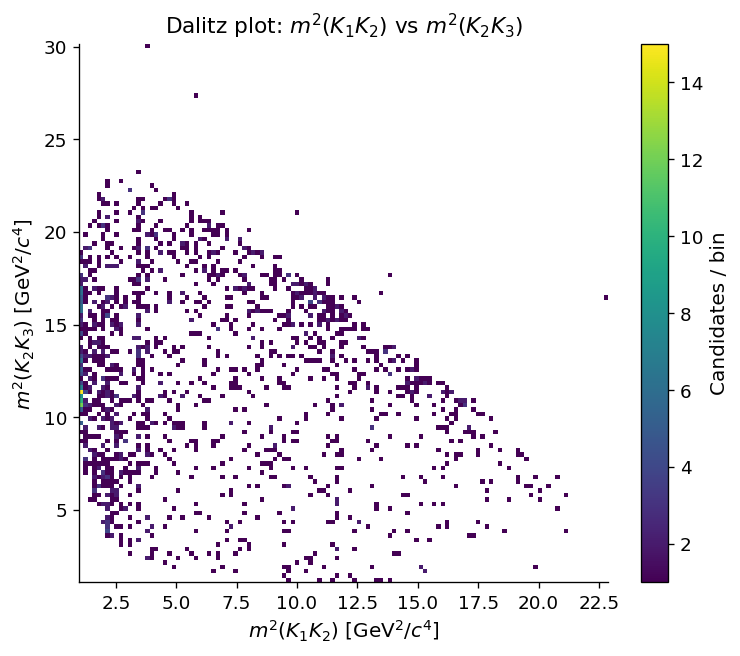

(<Figure size 768x672 with 2 Axes>,
 <Axes: title={'center': 'Dalitz plot: $m^2(K_1K_2)$ vs $m^2(K_2K_3)$'}, xlabel='$m^2(K_1K_2)$ [GeV$^2/c^4$]', ylabel='$m^2(K_2K_3)$ [GeV$^2/c^4$]'>)

In [7]:
plot_dalitz_hist2d(
    analysis_df,
    "m_K1K2_sq",
    "m_K2K3_sq",
    r"$m^2(K_1K_2)$ [GeV$^2/c^4$]",
    r"$m^2(K_2K_3)$ [GeV$^2/c^4$]",
    r"Dalitz plot: $m^2(K_1K_2)$ vs $m^2(K_2K_3)$",
    "dalitz_mK1K2_vs_mK2K3.png",
)


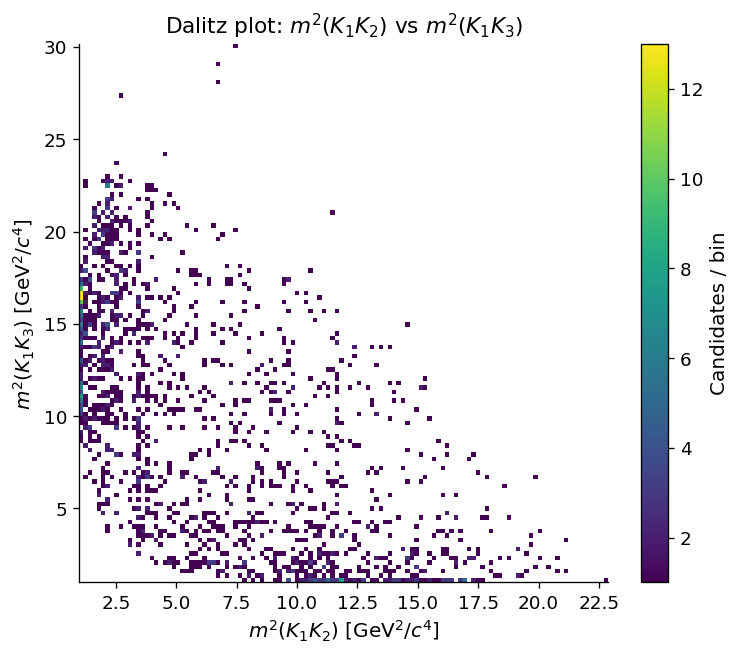

(<Figure size 768x672 with 2 Axes>,
 <Axes: title={'center': 'Dalitz plot: $m^2(K_1K_2)$ vs $m^2(K_1K_3)$'}, xlabel='$m^2(K_1K_2)$ [GeV$^2/c^4$]', ylabel='$m^2(K_1K_3)$ [GeV$^2/c^4$]'>)

In [8]:
plot_dalitz_hist2d(
    analysis_df,
    "m_K1K2_sq",
    "m_K1K3_sq",
    r"$m^2(K_1K_2)$ [GeV$^2/c^4$]",
    r"$m^2(K_1K_3)$ [GeV$^2/c^4$]",
    r"Dalitz plot: $m^2(K_1K_2)$ vs $m^2(K_1K_3)$",
    "dalitz_mK1K2_vs_mK1K3.png",
)


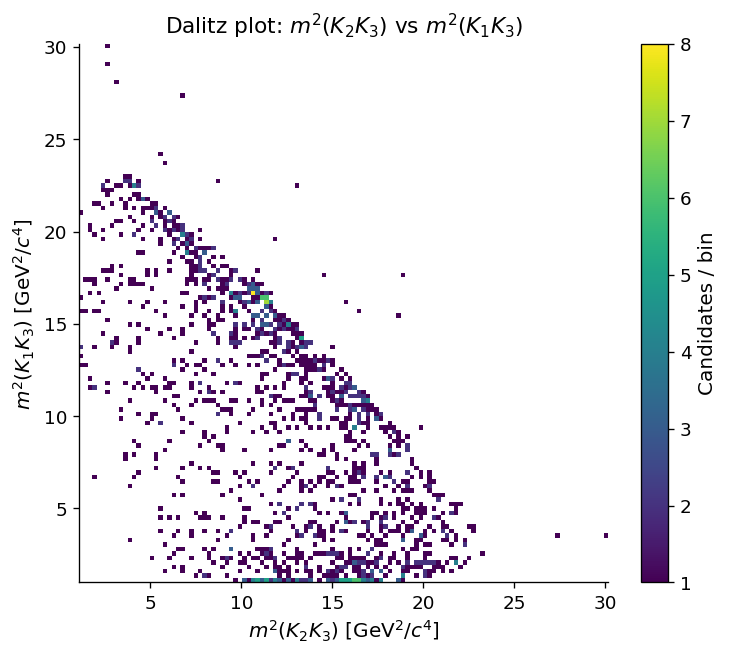

(<Figure size 768x672 with 2 Axes>,
 <Axes: title={'center': 'Dalitz plot: $m^2(K_2K_3)$ vs $m^2(K_1K_3)$'}, xlabel='$m^2(K_2K_3)$ [GeV$^2/c^4$]', ylabel='$m^2(K_1K_3)$ [GeV$^2/c^4$]'>)

In [9]:
plot_dalitz_hist2d(
    analysis_df,
    "m_K2K3_sq",
    "m_K1K3_sq",
    r"$m^2(K_2K_3)$ [GeV$^2/c^4$]",
    r"$m^2(K_1K_3)$ [GeV$^2/c^4$]",
    r"Dalitz plot: $m^2(K_2K_3)$ vs $m^2(K_1K_3)$",
    "dalitz_mK2K3_vs_mK1K3.png",
)


## Interpretation

The Dalitz distributions provide a first look at the phase-space population of selected candidates. A more realistic amplitude-analysis workflow would compare these maps between B+ and B- samples, subtract backgrounds, correct efficiency variations, and model resonant components explicitly.
